# Neural Green's Operators (NGOs) for the time-dependent diffusion problem

Before running this notebook, be sure you installed the right packages according to the README.md. Running this notebook from top to bottom should give you within a few seconds a reasonably accurate trained model NGO, a plot of a true solution versus the model NGO prediction, and a plot of the prediction error of the model NGO versus the length scale of the test data. For higher accuracy, set the variables 'N_samples_train'=10000, 'N_samples_val'=1000 and 'epochs'=5000. For higher statistics in the error versus length scale plot, set the number of test data samples to 100 or 1000.

### Imports

In [1]:
from ngo.ml.trainer import train
from ngo.ml.customlosses import *
from ngo.ml.systemnets import *
from ngo.numericalanalysis.basisfunctions import *
from ngo.ml.modelloader import *
from ngo.numericalanalysis.quadrature import *
from ngo.testproblems.timedependentdiffusion.NeuralOperator import NeuralOperator
from ngo.testproblems.timedependentdiffusion.DataModule import DataModule
from ngo.testproblems.timedependentdiffusion.manufacturedsolutions import *
import matplotlib.pyplot as plt
hparams = {}

/home/prins/st7/my_venv/lib/python3.13/site-packages/lightning_fabric/__init__.py:41: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.


### Data type and device

In [2]:
hparams['dtype'] = torch.float64 #Model dtype
hparams['accelerator'] = 'gpu' # Can be set to 'cpu' if desired
hparams['device'] = 'cuda:0' # Can be set to 'cpu' if desired

### Training data (manufactured solutions)

In [3]:
#Training data
hparams['N_samples_train'] = 1000 #Number of training samples
hparams['N_samples_val'] = 100 #Number of validation samples
hparams['l_min'] = torch.tensor([0.5,0.5,0.5], dtype=hparams['dtype'], device=hparams['device']) #Minimum GRF length scale per dimension
hparams['l_max'] = torch.tensor([1,1,1], dtype=hparams['dtype'], device=hparams['device']) #Maximum GRF length scale per dimension
hparams['d'] = len(hparams['l_min']) #Number of spatial dimensions
hparams['b_theta_min'] = 1 #minimum coefficient field mean
hparams['b_theta_max'] = 1 #maximum coefficient field mean
hparams['c_theta_min'] = 0 #minimum coefficient field standard deviation
hparams['c_theta_max'] = 0.2 #maximum coefficient field standard deviation
hparams['b_u_min']  = -1 #minimum solution field mean   
hparams['b_u_max']  = 1 #maximum solution field mean
hparams['c_u_min']  = 0 #minimum solution field standard deviation
hparams['c_u_max']  = 1 #maximum solution field standard deviation
hparams['n_RBF'] = (11,11,11) #Number of basis functions per dimension for data generation

### Training settings

In [4]:
hparams['output_coefficients'] = True #Whether the NN outputs coefficients (True) or values at quadrature points (False)
hparams['solution_loss'] = relativeL2norm_coefficients #For data NGO and model NGO. See src/ngo/ml/customlosses.py for the options
hparams['matrix_loss'] = None #Option: "relativematrixnorm" for data-free NGO
hparams['metric'] = relativeL2norm_coefficients
hparams['optimizer'] = torch.optim.Adam
hparams['learning_rate'] = 1e-3
hparams['batch_size'] = 100
hparams['epochs'] = 100 #Default for model NGO is 5000, for data NGO 20000

### Bases


In [5]:
hparams['N_i'] = (2,10,10) #Number of basis functions per dimension
hparams['p'] = (1,3,3) #Polynomial order per dimension (in case of B-spline basis)
hparams['C'] = (0,2,2) #Continuity along elements per dimension (in case of B-spline basis)
hparams['N'] = np.prod(hparams['N_i']) #Number of  basis degrees of freedom
hparams['test_bases'] = [BSplineBasis(N=hparams['N_i'][0], p=hparams['p'][0], C=hparams['C'][0], dtype=hparams['dtype'], device=hparams['device']), #basis functions in t
                         BSplineBasis(N=hparams['N_i'][1], p=hparams['p'][1], C=hparams['C'][1], dtype=hparams['dtype'], device=hparams['device']), #basis functions in x
                         BSplineBasis(N=hparams['N_i'][2], p=hparams['p'][2], C=hparams['C'][2], dtype=hparams['dtype'], device=hparams['device'])] #basis functions in y (see src/ngo/ml/basisfunctions.py for the options)
hparams['trial_bases'] = hparams['test_bases']
hparams['Dt'] = 0.001 #Time step size

### Quadrature

In [6]:
hparams['quadrature'] = 'Gauss-Legendre' #Quadrature rule, either "Gauss-Legendre" or "uniform" (for FNO)
hparams['n_elements'] = (1,3,3) #Number of elements of the quadrature grid
hparams['Q'] = (2,99,99) #Number of quadrature points per dimension (for all elements, not per element)
hparams['quadrature_L'] = 'Gauss-Legendre' #Loss quadrature rule, either "Gauss-Legendre" or "uniform" (for FNO)
hparams['n_elements_L'] = (1,3,3) #Number of elements of the loss quadrature grid
hparams['Q_L'] = (2,99,99) #Number of loss quadrature points per dimension (for all elements, not per element)

### System net

In [7]:
hparams['modeltype'] = 'data NGO' #Options: "NN" for bare NN, "DeepONet", "VarMiON", "data NGO", "model NGO"
hparams['systemnet'] = CNN_3dto2d #See src/ngo/ml/systemnets.py for the options
hparams['N_w'] = 30000 #Number of trainable parameters (upper bound, not exact)
hparams['bias'] = False
hparams['skipconnections'] = True #In case of a symmetric CNN -> U-Net
# hparams['kernel_sizes'] = [2,2,5,10,10,5,2,2] #In case of a CNN. See paper appendix for kernel sizes for all different models
hparams['kernel_sizes'] = [(1,1,1), (1,1,1), (1,2,2), (2,5,5), (5,5), (2,2), (1,1), (20,20)] #In case of a CNN. See paper appendix for kernel sizes for all different models
hparams['bottleneck_size'] = 20 #MLP bottleneck size in case of a CNN (uses an MLP connection in the bottleneck)
hparams['outputactivation'] = nn.Tanhshrink() #Set to None for models other than model NGO. For the systemnet. Hidden layer activations are ReLU by default

### Additional inductive bias

In [8]:
hparams['Neumannseries'] = False #Whether to use Neumann series expansion (only for model NGOs and data-free NGOs)
hparams['Neumannseries_order'] = 1 #Order of the Neumann series expansion (only for model NGOs and data-free NGOs)
hparams['scaling_equivariance'] = False #Whether to use scaling equivariance (only for NGOs)
hparams['Mnorm_scaling'] = False #Whether to scale the system matrix norm during training (only for data NGO)
hparams['Mnorm_max'] = 0.8 #Target maximum system matrix norm (only for data NGO)
hparams['tol'] = 1e-3 #Power iteration tolerance for estimating the system matrix norm (only for data NGO)
hparams['max_iterations'] = 1000 #Power iteration max. number of iterations for estimating the system matrix norm (only for data NGO)
hparams['alpha'] = 0 #Dissipation parameter (set to 0 by default)
hparams['gamma_stabilization'] = 100 #Stabilization constant for the system matrix
hparams['massconservation'] = False #Whether to enforce mass conservation
hparams['dissipation'] = False #Whether to enforce a dissipation
hparams['stabilization_in_massconservation'] = False #Whether to include the stabilization term in the mass conservation constraint

### Directory to save the model and tensorboard log, model name

In [9]:
logdir = './nnlogs' #Location for the tensorboard log files
sublogdir = 'tdd' #Folder name in the "nnlogs" directory
label = 'ngo' #Give your model a name
hparams['logdir'] = logdir+'/'+sublogdir+'/'+label
hparams['label'] = label

### Train the model

In [10]:
train(NeuralOperator, DataModule, hparams, logdir, sublogdir, label)

/data/storage7/prins/git/ngo-pde-gk/src/ngo/testproblems/timedependentdiffusion/NeuralOperator.py:110: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.x_0 = torch.tensor(x_0, dtype=self.dtype, device=self.device)
/data/storage7/prins/git/ngo-pde-gk/src/ngo/trainingdata/GRF.py:53: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.b = torch.tensor(b, dtype=self.dtype, device=self.device)
/data/storage7/prins/git/ngo-pde-gk/src/ngo/trainingdata/GRF.py:54: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.c = torch.tensor(c, dtype=self.d

Discretizing input functions...
Assembling F...
Assembling d...
Calculating conserved quantity...


/home/prins/st7/my_venv/lib/python3.13/site-packages/lightning_fabric/plugins/environments/slurm.py:204: The `srun` command is available on your system but is not used. HINT: If your intention is to run Lightning on SLURM, prepend your python command with `srun` like so: srun python /home/prins/st7/my_venv/lib/python3.13/site-packages ...
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
/data/storage7/prins/git/ngo-pde-gk/src/ngo/testproblems/timedependentdiffusion/DataModule.py:121: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.F = torch.tensor(self.F, dtype=self.hparams['dtype'])
/data/storage7/prins/git/ngo-pde-gk/src/ngo/testproblems/timedependentdiffusion/DataModule.py:122: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clon

Discretizing output function...


Sanity Checking: |          | 0/? [00:00<?, ?it/s]

...

Validation: |          | 0/? [00:00<?, ?it/s]

0.03727551040380422


Validation: |          | 0/? [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=100` reached.


0.03663395419969689
Training time: 17.058480s


### Load the model


In [11]:
projection = loadmodelfromlabel(model=NeuralOperator, label=label, logdir=logdir, sublogdir=sublogdir, device=hparams['device'])
projection.hparams['modeltype'] = 'projection'
projection.hparams['dtype'] = torch.float64
projection.hparams['precision'] = 64
projection.__init__(projection.hparams)

modelNGO = loadmodelfromlabel(model=NeuralOperator, label=label, logdir=logdir, sublogdir=sublogdir, device=hparams['device'])

models = {'Projection': projection,
             'Model NGO': modelNGO}

/data/storage7/prins/git/ngo-pde-gk/src/ngo/ml/modelloader.py:29: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ckpt = torch.load(logdir + '/' + sublogdir + '/' + label + '/

### Animation of true, projected and predicted solutions

In [12]:
tau = 0.5 #time scale of manufactured solution test sample
l = 0.5 #length scale of manufactured solution test sample
timesteps = 10 #number of time steps

In [13]:
N_samples = 1

t = torch.linspace(0, 1, timesteps, dtype=hparams['dtype'], device=hparams['device'])
x = torch.linspace(0, 1, 101, dtype=hparams['dtype'], device=hparams['device'])
y = torch.linspace(0, 1, 101, dtype=hparams['dtype'], device=hparams['device'])
X = t, x, y
    
N_samples = 1
    
manufacturedsolutions = ManufacturedSolutions(N_samples,
                                            hparams['d'],
                                            hparams['l_min'],
                                            hparams['l_max'],
                                            hparams['b_u_min'],
                                            hparams['b_u_max'],
                                            hparams['c_u_min'],
                                            hparams['c_u_max'],
                                            hparams['b_theta_min'],
                                            hparams['b_theta_max'],
                                            hparams['c_theta_min'],
                                            hparams['c_theta_max'],
                                            hparams['device'],
                                            hparams['dtype'],
                                            hparams['n_RBF'])
theta = manufacturedsolutions.theta
f = manufacturedsolutions.f
eta_y0 = manufacturedsolutions.eta_y0
eta_yL = manufacturedsolutions.eta_yL
g_x0 = manufacturedsolutions.g_x0
g_xL = manufacturedsolutions.g_xL
u = manufacturedsolutions.u
u0 = manufacturedsolutions.u0

<>:42: SyntaxWarning: invalid escape sequence '\m'
<>:53: SyntaxWarning: invalid escape sequence '\h'
<>:42: SyntaxWarning: invalid escape sequence '\m'
<>:53: SyntaxWarning: invalid escape sequence '\h'
/data/storage7/prins/temp/ipykernel_791917/1869664832.py:42: SyntaxWarning: invalid escape sequence '\m'
  ax.set_title('projection $u^{\mathrm{p}}$', fontsize=size_title)
/data/storage7/prins/temp/ipykernel_791917/1869664832.py:53: SyntaxWarning: invalid escape sequence '\h'
  ax.set_title('Model NGO $\hat{u}$', fontsize=size_title)


torch.Size([1, 10, 101, 101])


/data/storage7/prins/temp/ipykernel_791917/1869664832.py:42: SyntaxWarning: invalid escape sequence '\m'
  ax.set_title('projection $u^{\mathrm{p}}$', fontsize=size_title)
/data/storage7/prins/temp/ipykernel_791917/1869664832.py:53: SyntaxWarning: invalid escape sequence '\h'
  ax.set_title('Model NGO $\hat{u}$', fontsize=size_title)


ValueError: operands could not be broadcast together with shapes (1,100,100) (3,) 

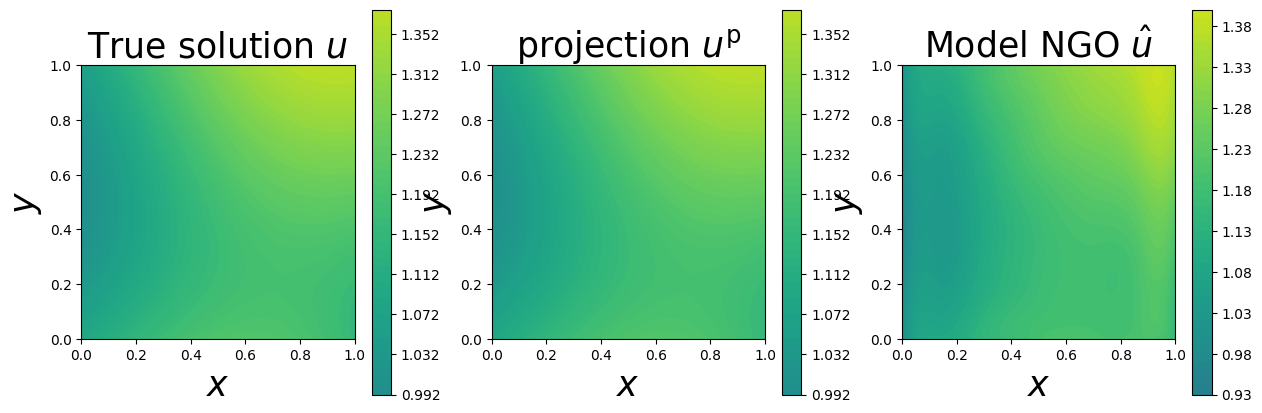

: 

In [ ]:
# Animation parameters
size_title = 20
size_ticklabels = 15
size_axeslabels = 25
t_values = np.linspace(0, (timesteps-1)*projection.hparams['Dt'], timesteps)  # Time steps for the animation
# Create grid
size_title = 25
size_ticklabels = 15
size_axeslabels = 25

fig, axs = plt.subplots(1, 3, figsize=(15, 5))
fig.subplots_adjust(left=None, bottom=None, right=None, top=None, wspace=0.2, hspace=0)

u_exact = u.forward(X)
print(u_exact.shape)
u_proj = projection.simforward(theta, f, eta_y0, eta_yL, g_x0, g_xL, u0, X, u)
u_hat_modelNGO = modelNGO.simforward(theta, f, eta_y0, eta_yL, g_x0, g_xL, u0, X, u)
u_min = torch.amin(u_exact)
u_max = torch.amax(u_exact)

X_mesh, Y_mesh = torch.meshgrid(X[1], X[2], indexing='ij')

ax = axs[0]
fig0 = ax.contourf(X_mesh.cpu(), Y_mesh.cpu(), u_exact[0,0].cpu(), levels=50, vmin=torch.amin(u_exact[0]), vmax=torch.amax(u_exact[0]))
ax.ticklabel_format(style='sci', scilimits=[-3,3])
ax.set_xlabel(r'$x$', fontsize=size_axeslabels)
ax.set_ylabel(r'$y$', fontsize=size_axeslabels)
ax.set_xlim(0,1)
ax.set_ylim(0,1)
ax.set_aspect('equal')
ax.set_title('True solution $u$', fontsize=size_title)
plt.colorbar(fig0)

ax = axs[1]
fig1 = ax.contourf(X_mesh.cpu(), Y_mesh.cpu(), u_proj[0,0].cpu(), levels=50, vmin=torch.amin(u_exact[0]), vmax=torch.amax(u_exact[0]))
ax.ticklabel_format(style='sci', scilimits=[-3,3])
ax.set_xlabel(r'$x$', fontsize=size_axeslabels)
ax.set_ylabel(r'$y$', fontsize=size_axeslabels)
ax.set_xlim(0,1)
ax.set_ylim(0,1)
ax.set_aspect('equal')
ax.set_title('projection $u^{\mathrm{p}}$', fontsize=size_title)
plt.colorbar(fig1)

ax = axs[2]
fig2 = ax.contourf(X_mesh.cpu(), Y_mesh.cpu(), u_hat_modelNGO[0,0].detach().cpu(), levels=50, vmin=torch.amin(u_exact[0]), vmax=torch.amax(u_exact[0]))
ax.ticklabel_format(style='sci', scilimits=[-3,3])
ax.set_xlabel(r'$x$', fontsize=size_axeslabels)
ax.set_ylabel(r'$y$', fontsize=size_axeslabels)
ax.set_xlim(0,1)
ax.set_ylim(0,1)
ax.set_aspect('equal')
ax.set_title('Model NGO $\hat{u}$', fontsize=size_title)
plt.colorbar(fig2)

quadrature = UniformQuadrature(Q=[1,100,100], dtype=hparams['dtype'], device=hparams['device'])
x = quadrature.xi
w = quadrature.w
w = w*projection.hparams['Dt']
x[:,0] = 0

projection.timestep = 0
x_scaled = np.copy(x)

# Update function for the animation
def update(t):
    print(t)
    u_exact = discretize_functions(u, x_scaled)
    u_proj = projection.simforward(theta, f, eta_y0, eta_yL, g_x0, g_xL, u0, x_scaled, u)
    u_hat_modelNGO = modelNGO.simforward(theta, f, eta_y0, eta_yL, g_x0, g_xL, u0, x_scaled, u)

    ax = axs[0]
    tripcolor_plot = ax.tripcolor(x[:,1], x[:,2], u_exact[0], vmin=u_min, vmax=u_max)
    ax = axs[1]
    tripcolor_plot = ax.tripcolor(x[:,1], x[:,2], u_proj[0], vmin=u_min, vmax=u_max)
    ax = axs[2]
    tripcolor_plot = ax.tripcolor(x[:,1], x[:,2],u_hat_modelNGO[0], vmin=u_min, vmax=u_max)


    plt.suptitle(f'$t/T=${t:.3f}', fontsize=30)

    projection.translate_quadrature_t()
    projection.timestep += 1
    modelNGO.translate_quadrature_t()
    modelNGO.timestep += 1
    x_scaled[:,0] = x_scaled[:,0] + projection.hparams['Dt']

# Create the animation
ani = FuncAnimation(fig, update, frames=t_values, repeat=False)

# Save or display animation
ani.save('animation_timestepping_NGO.gif', writer='pillow', fps=10)
plt.show()  # Uncomment to display the animation


### Plot of error versus test data length scale


In [ ]:
N_samples = 10 #Number of test samples per length scale
l = np.array([0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1]) #Length scales to test on
alpha = 0.05 #Plot confidence interval for the error bars. alpha=0.05 gives 95% confidence intervals
quadrature = GaussLegendreQuadrature(n_elements=(3,3), Q=(99,99)) #L2 error function quadrature
x = quadrature.xi
w = quadrature.w

In [ ]:
size_ticklabels = 15
size_axeslabels = 20
linestyles=['-','--']
colors = ['black','C0']

q_low = alpha/2
q_high = 1 - q_low

L2_scaled_avg = np.zeros((len(models),len(l)))
yerr = np.zeros((len(models),2,len(l)))

    
for i in range(len(l)):
    print("Length scale: "+ str(l[i]))
    dataset = ManufacturedSolutionsSet(N_samples=N_samples, variables=['x','x'], l_min=[l[i],l[i]], l_max=[l[i],l[i]])
    theta = dataset.theta
    f = dataset.f
    etat = dataset.eta_yL
    etab = dataset.eta_y0
    gl = dataset.g_x0
    gr = dataset.g_xL
    u = dataset.u
    m=0
    for model in models:
        u_exact = discretize_functions(u, x)
        u_hat = models[str(model)].simforward(theta, f, etab, etat, gl, gr, x, u)
        L2_scaled_array = weightedrelativeL2_set(w, u_hat, u_exact)
        L2_scaled_avg[m,i] = np.average(L2_scaled_array)
        q_l = np.quantile(L2_scaled_array, q_low)
        q_h = np.quantile(L2_scaled_array, q_high)
        yerr[m,:,i] = np.array([L2_scaled_avg[m,i] - q_l, -L2_scaled_avg[m,i] + q_h])
        m+=1

fig, ax = plt.subplots(1,1, figsize=(6, 4))
fig.subplots_adjust(left=None, bottom=None, right=None, top=None, wspace=0.4, hspace=0.4)

plots = []
plots.append(ax.axvspan(0.5,1, color='black', alpha=0.1, label='Training data range'))
m=0
ax.tick_params(axis='both', labelsize=size_ticklabels)
ax.set_xlabel(r'Length scale $\lambda/L$', fontsize=size_axeslabels)
ax.set_ylabel(r'Rel. L2 error $\frac{||\hat{u}-u||_2}{||u||_2}$', fontsize=size_axeslabels)
ax.set_yscale('log')
ax.set_xlim(0, 1.05)
ax.grid()
for model in models:
    plots.append(ax.errorbar(l, L2_scaled_avg[m], yerr=yerr[m], fmt=".-", capsize=6, ms=15, label=str(model), color=colors[m], linestyle=linestyles[m]))
    m+=1
plt.legend(fontsize=10, ncols=2)

plt.savefig("errorversuslengthscale.png", bbox_inches='tight')


Length scale: 0.05


TypeError: NeuralOperator.simforward() missing 1 required positional argument: 'u'